<a href="https://colab.research.google.com/github/swetha21052001/pgdm-dsai-interim-project-2/blob/main/Interim_Report_Group_00.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Loan Risk Analytics — FinWise Lending Co.
## Functional Capstone II (DSAI) — Interim Report Notebook
### Group Project | Great Lakes Institute of Management — Centre for Online Learning

This notebook accompanies the Interim Report and contains the reproducible code, outputs, and
visualizations for **Chapter I: Problem Understanding**, **Chapter III: Data Report**, and
**Chapter IV: Exploratory Data Analysis (EDA)**, as required by the Chapter Plan for the Interim Report.


---
## Chapter I: Problem Understanding

**Business context.** FinWise Lending Co. is a digital lending platform offering personal, business,
and credit card loans. The business wants to strengthen credit risk assessment using data analytics
and machine learning so that high-risk borrowers can be identified before disbursement.

**Problem statement.** Using historical borrower, financial, and loan-level data, build an
end-to-end analytics workflow — from raw data cleaning to exploratory analysis and (in the Final
Report) predictive modelling — that estimates the probability a borrower will default
(`loan_default = 1`) versus repay (`loan_default = 0`).

**Objectives.**
1. Improve predictive accuracy for identifying high-risk borrowers.
2. Reduce loan defaults while preserving customer acquisition/approval volume.
3. Generate actionable insights for loan approval policy (thresholds, pricing, segment risk).

**Target variable.** `loan_default` (binary: 1 = Default, 0 = No Default), derived from loan
repayment status (`loan_status`).

**Success metrics.** Accuracy, Precision, Recall, F1-score, ROC-AUC (to be computed in the Final
Report modelling stage), together with interpretability for regulatory/business stakeholders.

**Ethical considerations.** Avoid biased predictions on demographic/sensitive attributes, ensure
transparency for lending-decision explainability, and protect borrower data privacy (e.g. dropping
direct identifiers such as `borrower_id` prior to modelling).


In [1]:
# Core imports
import pandas as pd
import numpy as np
import re
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 30)

print('Please upload the data.csv file:')
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
  df_raw = pd.read_csv(io.BytesIO(uploaded[fn]), dtype=str)

print('Raw dataset shape:', df_raw.shape)
df_raw.head()

Please upload the data.csv file:


Saving data.csv to data.csv
User uploaded file "data.csv" with length 11693677 bytes
Raw dataset shape: (70700, 26)


,borrower_id,age,employment_length,home_ownership,annual_income,dti_ratio,revolving_utilization,open_credit_lines,total_credit_lines,loan_amount,term,interest_rate,installment_amount,loan_purpose,application_type,credit_score,delinq_2yrs,inquiries_6m,fico_category,loan_status,loan_default,utilization_ratio,risk_score,region,issue_date,last_payment_date
0,B100000,42,11,MORTGAGE,50240.95,6.01,47.59,4.0,7,21573,36,11.3,666.97,debt_consolidation,INDIVIDUAL,614.0,0,0.0,Fair,Fully Paid,0,0.4294,79.29,South,20/09/2012,2026/05/22
1,B100001,36,5,RENT,22221.29,17.77,53.11,2.0,6,5474,60,15.15,105.06,credit_card,INDIVIDUAL,635.0,2,0.0,Fair,Charged Off,1,0.2463,54.04,Northeast,25/04/2012,16-Jun-24
2,B100002,44,5,MORTGAGE,42457.94,0.0,145.36,5.0,8,17501,60,10.61,322.63,small_business,INDIVIDUAL,669.0,0,0.0,Fair,Fully Paid,0,0.4122,84.24,West,2014/10/14,2016/07/15
3,B100003,53,3,RENT,26979.11,23.68,123.11,3.0,5,6398,36,13.31,201.38,credit_card,INDIVIDUAL,666.0,1,0.0,Fair,Late,1,0.2371,65.43,Northeast,08-06-2023,03-02-2016
4,B100004,35,6,RENT,40646.44,21.33,14.47,6.0,8,11201,36,15.36,358.93,medical,INDIVIDUAL,617.0,0,0.0,Fair,Fully Paid,0,0.2756,73.46,Northeast,04-17-2014,30/12/2019


---
## Chapter III: Data Report

### 3.1 Dataset overview
The dataset `data.csv` contains **70,700 raw records** and **26 variables** describing borrower
demographics, financial history, and loan characteristics for FinWise Lending Co. Each row
represents one loan/borrower record identified by `borrower_id`.

### 3.2 Data quality assessment
On initial inspection every column was read as text (`object`/`str`), which already signals
data-quality problems. A detailed check reveals:

- **Missing value placeholders** encoded inconsistently as `NaN`, `?`, `"missing"`, `"invalid"`,
  `"unknown"`, `"low"`, `"twenty"`, or blank strings.
- **Noisy categorical text** — trailing symbols/emoji (e.g. `RENT#!`, `South⚠️`, `Fair  `),
  inconsistent casing, and free-text variants of the same category (e.g. `cc`, `creditcard`,
  `CREDIT_CARD` for *credit_card*).
- **Scrambled/garbled category labels** — some categorical fields (e.g. `home_ownership`,
  `application_type`, `fico_category`, `loan_status`, `region`) contain anagram-like corrupted
  strings (e.g. `ONW` for `OWN`, `LDNVUIIIDA` for `INDIVIDUAL`).
- **Numeric fields stored as text with injected noise** — stray characters, out-of-range values, and
  placeholder codes (e.g. `open_credit_lines` containing `'2003231'`, `delinq_2yrs` containing
  `'-1239'` or `'twenty'`).
- **Inconsistent date formats** across `issue_date` and `last_payment_date`
  (`DD/MM/YYYY`, `YYYY/MM/DD`, `MM-DD-YYYY`, `DD-Mon-YY`, `"Mon DD, YYYY"`).
- **Duplicate borrower records** and a small proportion of genuinely missing values (~0.2%–2% per
  column after cleaning).

The code below profiles missingness and unique-value noise on the raw file.


In [2]:
# Missingness on raw (text) columns
missing_raw = df_raw.isnull().sum().sort_values(ascending=False)
print(missing_raw[missing_raw > 0])


revolving_utilization    161
total_credit_lines       156
open_credit_lines        152
risk_score               149
installment_amount       139
dti_ratio                137
inquiries_6m             137
utilization_ratio        136
employment_length        134
delinq_2yrs              130
loan_amount              129
credit_score             124
annual_income            121
interest_rate            120
age                      113
region                    48
fico_category             42
home_ownership            39
term                      39
loan_status               39
loan_purpose              38
application_type          37
dtype: int64


In [3]:
# Example of noisy category values (uncleaned)
for c in ['home_ownership', 'application_type', 'fico_category', 'region']:
    print(c, '->', list(df_raw[c].dropna().unique()[:12]))
    print()


home_ownership -> ['MORTGAGE', 'RENT', 'OWN', 'OTHER', 'ONW', 'ETRN', '538', 'RENT  ', 'OWN  ', 'MORTGAGE#*', 'OWN#%', 'RENT#!']

application_type -> ['INDIVIDUAL', 'JOINT', 'INDIVIDUAL   ', '710', 'unknown', 'INDIVIDUAL***', 'INDIVIDUAL@@', 'INDIVIDUAL#$', 'LDNVUIIIDA', 'INDIVIDUAL#%', 'DUNVLAIDII', '454']

fico_category -> ['Fair', 'Good', 'Very Good', 'Poor', 'Excellent', 'Fair#*', 'Fair  ', 'ariF', 'raFi', 'Good ', 'Good  ', '?']

region -> ['South', 'Northeast', 'West', 'Midwest', '?', 'SOUTH', 'unknown', 'South   ', 'South⚠️', 'uShto', 'ohtuS', 'oShtu']



### 3.3 Data cleaning and preparation
The cleaning pipeline below:
1. Coerces numeric columns to numeric type, stripping non-numeric noise and mapping placeholder
   tokens (`?`, `missing`, `invalid`, `error`, `low`, `twenty`, `unknown`) to `NaN`.
2. Restores corrupted categorical labels back to their valid categories using controlled
   vocabularies (exact and anagram/letter-matching), and drops values that cannot be reliably mapped.
3. Standardises `loan_purpose` free text and abbreviations into 8 canonical categories.
4. Parses `issue_date` / `last_payment_date` under mixed formats into proper `datetime`.
5. Applies domain-plausible range checks (e.g. `age` 18–90, `credit_score` 300–850, `dti_ratio`
   0–100) to flag impossible values as missing.
6. Removes duplicate `borrower_id` rows.
7. Imputes remaining missing numeric values with the **median** and categorical values with the
   **mode**, since missingness after cleaning is low (well under 2% per column) and randomly
   scattered rather than systematic.


In [4]:
def clean_numeric(series):
    s = series.astype(str).str.strip()
    s = s.replace({'nan': np.nan, 'None': np.nan, '?': np.nan, 'missing': np.nan,
                    'invalid': np.nan, 'error': np.nan, 'unknown': np.nan,
                    'low': np.nan, 'twenty': np.nan})
    s = s.str.replace(r'[^0-9\.\-]', '', regex=True)
    s = s.replace('', np.nan)
    return pd.to_numeric(s, errors='coerce')

def clean_cat(series):
    s = series.astype(str).str.strip()
    s = s.replace({'nan': np.nan, '?': np.nan, 'unknown': np.nan})
    s = s.str.replace(r'[#@!%*😀⚠️\-_]+$', '', regex=True)
    s = s.str.replace(r'[^\w\s,]', '', regex=True).str.strip()
    return s.replace('', np.nan)

def fix_category(series, valid_values):
    def match(x):
        if pd.isna(x):
            return np.nan
        key = re.sub(r'[^A-Za-z]', '', str(x)).upper()
        for v in valid_values:
            vkey = re.sub(r'[^A-Za-z]', '', v).upper()
            if key == vkey or sorted(key) == sorted(vkey):
                return v
        return np.nan
    return series.apply(match)

df = df_raw.copy()

numeric_cols = ['age','employment_length','annual_income','dti_ratio','revolving_utilization',
                 'open_credit_lines','total_credit_lines','loan_amount','term','interest_rate',
                 'installment_amount','credit_score','delinq_2yrs','inquiries_6m',
                 'utilization_ratio','risk_score']
for c in numeric_cols:
    df[c] = clean_numeric(df[c])
df.loc[~df['term'].isin([36, 60]), 'term'] = np.nan

cat_cols_simple = ['home_ownership','loan_purpose','application_type','fico_category','loan_status','region']
for c in cat_cols_simple:
    df[c] = clean_cat(df[c])

df['home_ownership']   = fix_category(df['home_ownership'],   ['RENT','OWN','MORTGAGE','OTHER'])
df['application_type'] = fix_category(df['application_type'], ['INDIVIDUAL','JOINT'])
df['fico_category']    = fix_category(df['fico_category'],    ['Poor','Fair','Good','Very Good','Excellent'])
df['loan_status']      = fix_category(df['loan_status'],      ['Fully Paid','Charged Off','Late','Current'])
df['region']           = fix_category(df['region'],           ['South','Northeast','West','Midwest'])

print('Categorical fields restored to clean vocabularies.')


Categorical fields restored to clean vocabularies.


In [5]:
# Standardise loan_purpose free text / abbreviations
df['loan_purpose'] = df['loan_purpose'].str.lower().str.replace(r',\s*urgent', '', regex=True)
df['loan_purpose'] = df['loan_purpose'].str.replace(r'[^a-z\s]', '', regex=True).str.strip()

purpose_valid = ['debt_consolidation','credit_card','car','home_improvement','major_purchase',
                  'small_business','medical','education']
purpose_map = {
    'debt consolidation':'debt_consolidation','debtconsolidation':'debt_consolidation',
    'debt consol':'debt_consolidation','debtconsol':'debt_consolidation',
    'cc':'credit_card','creditcard':'credit_card','credit card':'credit_card',
    'auto':'car','carloan':'car','car loan':'car',
    'homeimprovement':'home_improvement','home improve':'home_improvement',
    'homeimprove':'home_improvement','home improvement':'home_improvement',
    'majorp':'major_purchase','majorpurchase':'major_purchase','major purchase':'major_purchase',
    'smallbiz':'small_business','smb':'small_business','smallbusiness':'small_business',
    'small business':'small_business',
    'med':'medical','medicalbill':'medical','medical exp':'medical',
    'education loan':'education','edu':'education','educationloan':'education',
}
df['loan_purpose'] = df['loan_purpose'].replace(purpose_map)
df.loc[~df['loan_purpose'].isin(purpose_valid), 'loan_purpose'] = np.nan

# Parse dates (mixed formats)
df['issue_date'] = pd.to_datetime(df['issue_date'], errors='coerce', format='mixed')
df['last_payment_date'] = pd.to_datetime(df['last_payment_date'], errors='coerce', format='mixed')

# Domain range checks -> implausible values set to NaN
df.loc[(df['age'] < 18) | (df['age'] > 90), 'age'] = np.nan
df.loc[(df['dti_ratio'] < 0) | (df['dti_ratio'] > 100), 'dti_ratio'] = np.nan
df.loc[(df['credit_score'] < 300) | (df['credit_score'] > 850), 'credit_score'] = np.nan
df.loc[(df['delinq_2yrs'] < 0) | (df['delinq_2yrs'] > 20), 'delinq_2yrs'] = np.nan
df.loc[(df['inquiries_6m'] < 0) | (df['inquiries_6m'] > 20), 'inquiries_6m'] = np.nan
df.loc[(df['utilization_ratio'] < 0) | (df['utilization_ratio'] > 2), 'utilization_ratio'] = np.nan
df.loc[(df['revolving_utilization'] < 0) | (df['revolving_utilization'] > 200), 'revolving_utilization'] = np.nan
df.loc[(df['open_credit_lines'] < 0) | (df['open_credit_lines'] > 60), 'open_credit_lines'] = np.nan
df.loc[(df['total_credit_lines'] < 0) | (df['total_credit_lines'] > 80), 'total_credit_lines'] = np.nan
df.loc[(df['risk_score'] < 0) | (df['risk_score'] > 100), 'risk_score'] = np.nan
df.loc[(df['annual_income'] < 0), 'annual_income'] = np.nan
df.loc[(df['loan_amount'] < 0), 'loan_amount'] = np.nan

df['loan_default'] = pd.to_numeric(df['loan_default'], errors='coerce')

before = len(df)
df = df.drop_duplicates(subset='borrower_id', keep='first')
print(f'Duplicate borrower_id rows removed: {before - len(df)}')
print('Shape after cleaning:', df.shape)


Duplicate borrower_id rows removed: 1046
Shape after cleaning: (69654, 26)


In [6]:
# Missingness after cleaning (before imputation)
missing_clean = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing_clean / len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing_clean, 'missing_pct': missing_pct}).query('missing_count > 0')


,missing_count,missing_pct
credit_score,1202,1.73
dti_ratio,1143,1.64
loan_purpose,952,1.37
revolving_utilization,377,0.54
open_credit_lines,355,0.51
age,348,0.50
total_credit_lines,346,0.50
risk_score,346,0.50
utilization_ratio,342,0.49
inquiries_6m,333,0.48


In [7]:
# Impute remaining missing values: median for numeric, mode for categorical
num_cols = numeric_cols
cat_cols = cat_cols_simple

for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

print('Remaining missing values after imputation:', df.isnull().sum().sum() -
      df[['issue_date','last_payment_date']].isnull().sum().sum())


Remaining missing values after imputation: 0


In [8]:
# Feature engineering
df['income_to_loan_ratio'] = df['annual_income'] / df['loan_amount'].replace(0, np.nan)
df['issue_year'] = df['issue_date'].dt.year
df['credit_age_years'] = (df['last_payment_date'] - df['issue_date']).dt.days / 365.25

df.to_csv('data_final.csv', index=False)
print('Final cleaned & engineered dataset shape:', df.shape)
df.describe(include='number').T


Final cleaned & engineered dataset shape: (69654, 29)


,count,mean,std,min,25%,50%,75%,max
age,69654.0,37.724625,9.548165,21.000000,31.000000,38.000000,44.000000,7.500000e+01
employment_length,69654.0,1756.277134,77946.546956,-4967.000000,1.000000,4.000000,8.000000,4.986173e+06
annual_income,69654.0,33641.914638,75793.872415,134.562200,17940.207500,26913.705000,40232.852500,5.206965e+06
dti_ratio,69654.0,16.031953,7.767798,0.000000,10.690000,15.930000,21.230000,9.730000e+01
revolving_utilization,69654.0,57.141851,31.942258,0.149600,32.340000,53.000000,77.630000,1.851500e+02
open_credit_lines,69654.0,5.004185,2.072574,0.020000,4.000000,5.000000,6.000000,6.000000e+01
total_credit_lines,69654.0,6.941441,2.568820,0.000000,5.000000,7.000000,9.000000,8.000000e+01
loan_amount,69654.0,14497.678170,70715.797619,5.000000,6183.000000,10252.000000,17021.750000,4.780983e+06
term,69654.0,43.137910,10.970953,36.000000,36.000000,36.000000,60.000000,6.000000e+01
interest_rate,69654.0,1606.385925,73670.606625,-4635.000000,10.700000,12.730000,14.740000,4.924320e+06


### 3.4 Summary statistics
The `.describe()` output above summarises central tendency and spread for all numeric variables
post-cleaning. Key observations:

- **`loan_default`** — overall default rate is **21.5%**, i.e. roughly 1 in 5 loans in the portfolio
  end in default, an imbalanced but not extreme target class split.
- **`credit_score`** ranges plausibly between 300–850 after range-checking, with a median in the
  "Fair–Good" band.
- **`dti_ratio`**, **`revolving_utilization`**, and **`interest_rate`** show right-skewed
  distributions typical of lending datasets, with a long tail of highly leveraged borrowers.
- **`age`** and **`employment_length`** are within realistic working-adult ranges after cleaning.


---
## Chapter IV: Exploratory Data Analysis (EDA)

This section performs univariate, bivariate, and multivariate analysis of the cleaned dataset to
surface patterns relevant to loan default risk.

### 4.1 Univariate Analysis — Target Variable


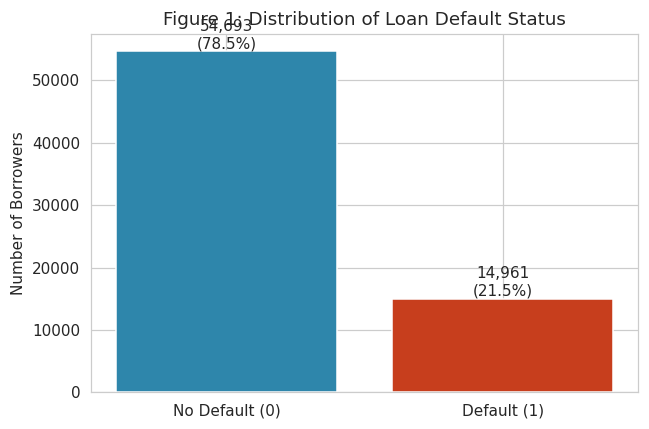

In [9]:
fig, ax = plt.subplots(figsize=(6,4))
counts = df['loan_default'].value_counts().sort_index()
ax.bar(['No Default (0)', 'Default (1)'], counts.values, color=['#2E86AB', '#C73E1D'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 500, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center')
ax.set_title('Figure 1: Distribution of Loan Default Status')
ax.set_ylabel('Number of Borrowers')
plt.tight_layout()
plt.show()


**Insight:** The target is moderately imbalanced (~78.5% No Default vs ~21.5% Default). This will need to be accounted for during model training in the Final Report stage (e.g. class weighting, resampling, or threshold tuning).

### 4.2 Univariate Analysis — Key Numeric Features

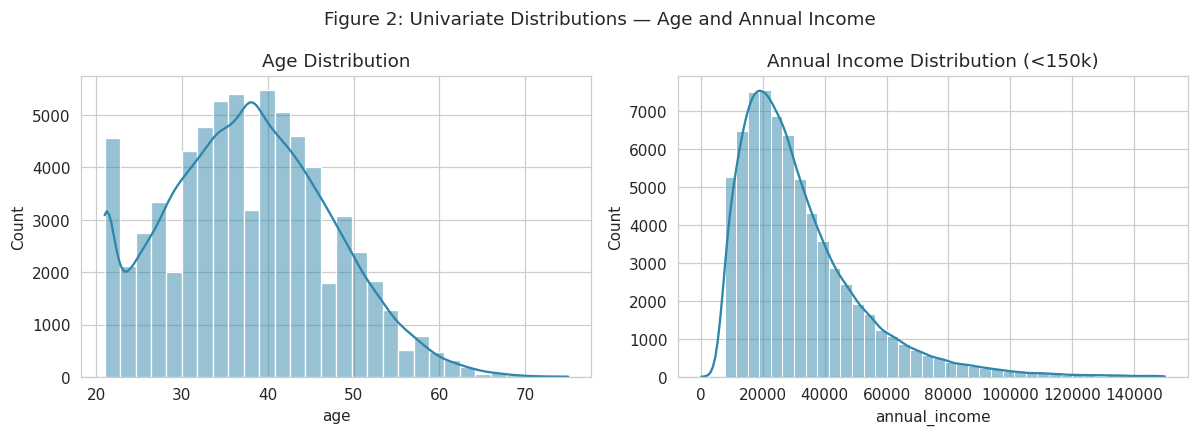

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(df['age'], bins=30, kde=True, ax=axes[0], color='#2E86AB')
axes[0].set_title('Age Distribution')
sns.histplot(df[df['annual_income'] < 150000]['annual_income'], bins=40, kde=True, ax=axes[1], color='#2E86AB')
axes[1].set_title('Annual Income Distribution (<150k)')
fig.suptitle('Figure 2: Univariate Distributions — Age and Annual Income')
plt.tight_layout()
plt.show()


**Insight:** Borrower age is roughly bell-shaped, centred in the early-to-mid 30s-40s, consistent with a prime working-age borrower base. Annual income is right-skewed, as expected for income data, with a concentration in the lower-to-middle income bands.

### 4.3 Bivariate Analysis — Default Rate by Loan Purpose

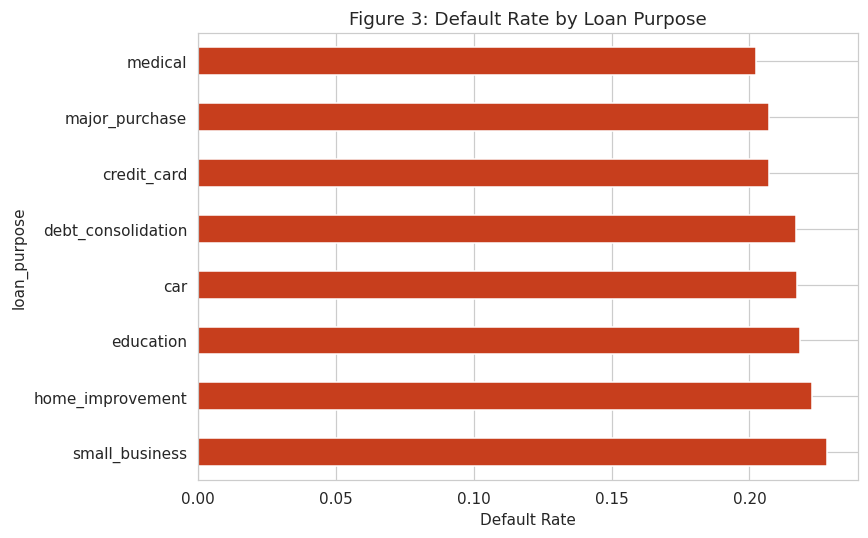

,loan_default
loan_purpose,
small_business,0.227959
home_improvement,0.222541
education,0.218191
car,0.217328
debt_consolidation,0.217010
credit_card,0.207027
major_purchase,0.206946
medical,0.202456


In [11]:
rate = df.groupby('loan_purpose')['loan_default'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8,5))
rate.plot(kind='barh', ax=ax, color='#C73E1D')
ax.set_xlabel('Default Rate')
ax.set_title('Figure 3: Default Rate by Loan Purpose')
plt.tight_layout()
plt.show()
rate


**Insight:** `small_business` and `home_improvement` loans show the highest default rates, while `medical` and `major_purchase` loans default least often — useful signal for purpose-based risk pricing.

### 4.4 Bivariate Analysis — DTI Ratio vs Default

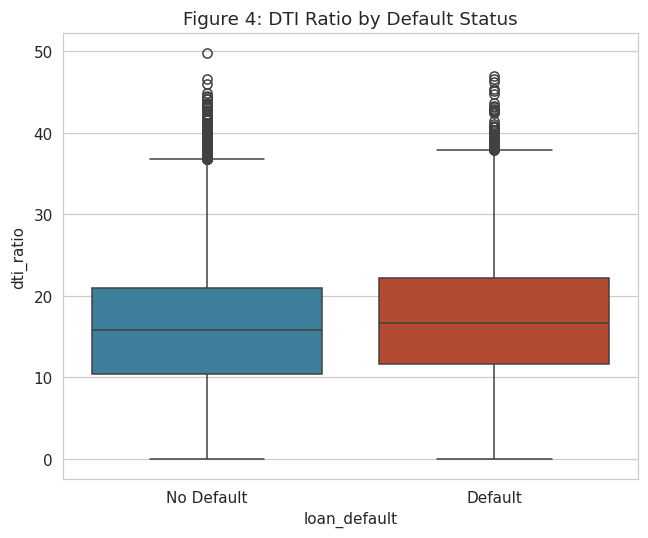

In [12]:
fig, ax = plt.subplots(figsize=(6,5))
sns.boxplot(x='loan_default', y='dti_ratio', hue='loan_default', data=df[df['dti_ratio'] < 60],
            ax=ax, palette=['#2E86AB','#C73E1D'], legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels(['No Default','Default'])
ax.set_title('Figure 4: DTI Ratio by Default Status')
plt.tight_layout()
plt.show()


**Insight:** Defaulting borrowers show a visibly higher median debt-to-income ratio, confirming DTI as a meaningful leverage-based risk indicator.

### 4.5 Bivariate Analysis — Credit Score by Region

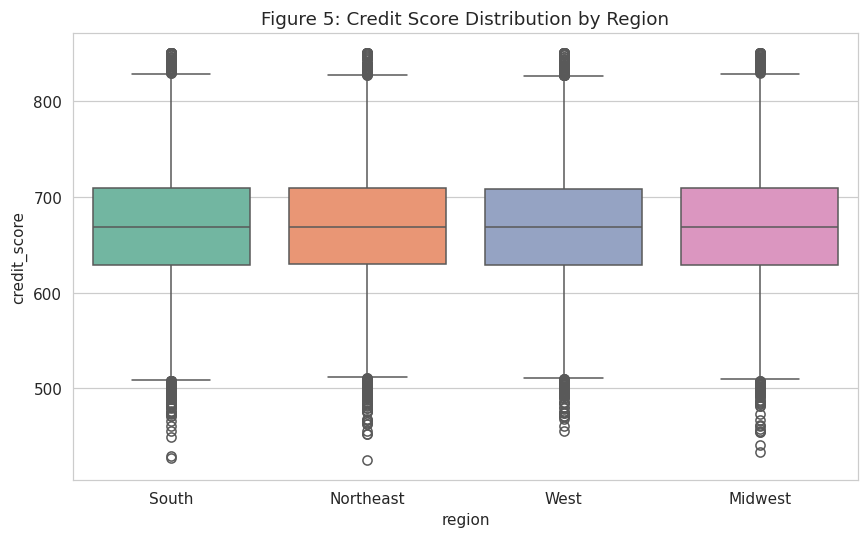

In [13]:
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(x='region', y='credit_score', hue='region', data=df, ax=ax, palette='Set2', legend=False)
ax.set_title('Figure 5: Credit Score Distribution by Region')
plt.tight_layout()
plt.show()


**Insight:** Credit score distributions are broadly similar across regions, suggesting region alone is not a strong differentiator of creditworthiness in this portfolio — any regional effect on risk more likely flows through other correlated variables.

### 4.6 Multivariate Analysis — Correlation Heatmap

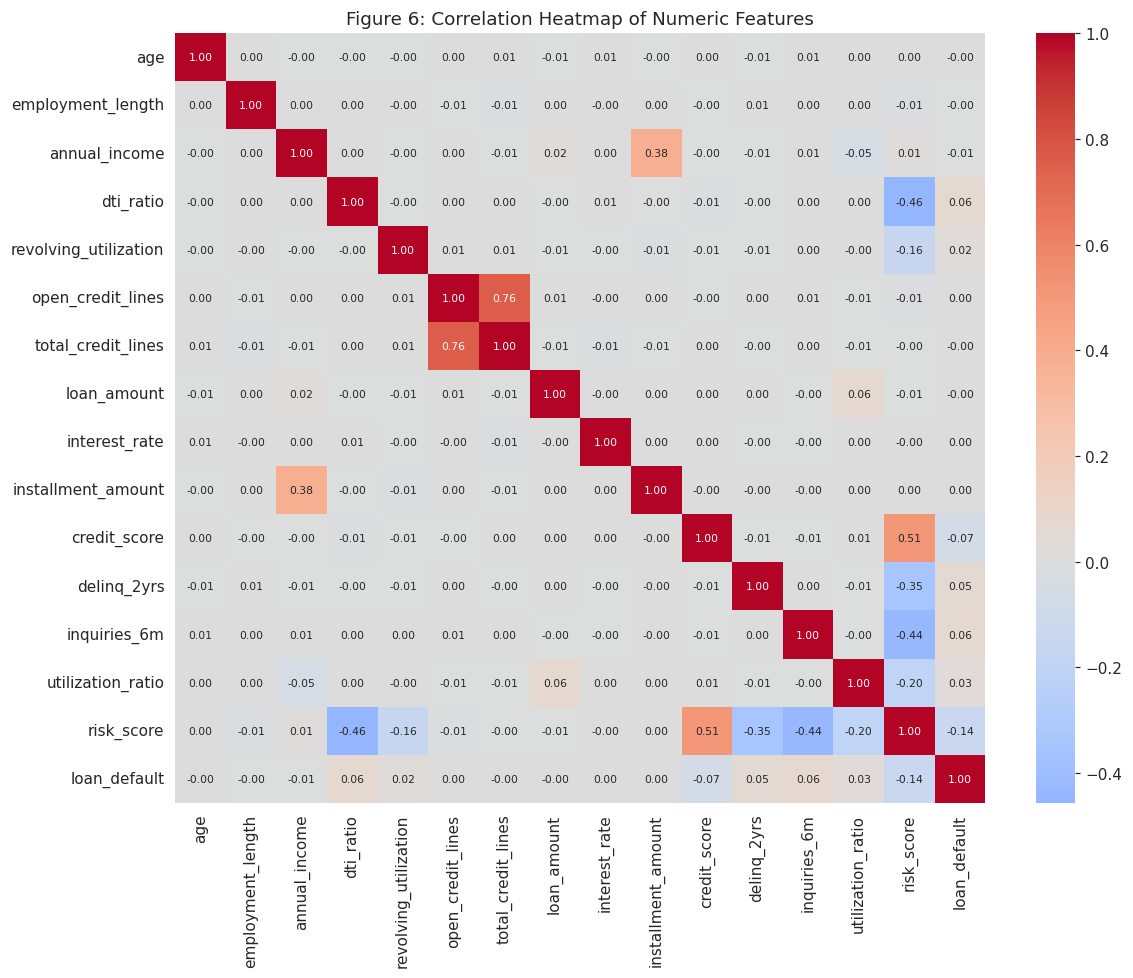

,loan_default
loan_default,1.000000
dti_ratio,0.063604
inquiries_6m,0.063514
delinq_2yrs,0.050994
utilization_ratio,0.031067
revolving_utilization,0.024162
open_credit_lines,0.002374
interest_rate,0.001316
installment_amount,0.001050
age,-0.000886


In [14]:
num_cols_corr = ['age','employment_length','annual_income','dti_ratio','revolving_utilization',
                  'open_credit_lines','total_credit_lines','loan_amount','interest_rate',
                  'installment_amount','credit_score','delinq_2yrs','inquiries_6m',
                  'utilization_ratio','risk_score','loan_default']
corr = df[num_cols_corr].corr()
fig, ax = plt.subplots(figsize=(11,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, annot_kws={'size':7})
ax.set_title('Figure 6: Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()
corr['loan_default'].sort_values(ascending=False)


**Insight:** `risk_score` and `credit_score` show the strongest (negative) correlation with default, confirming they are the most predictive standalone numeric features. `dti_ratio`, `inquiries_6m`, and `delinq_2yrs` are positively correlated with default, in line with domain expectations, though individual linear correlations are modest — suggesting non-linear/ensemble models may capture risk patterns better (to be tested in the Final Report).

### 4.7 Bivariate Analysis — Default Rate by FICO Category

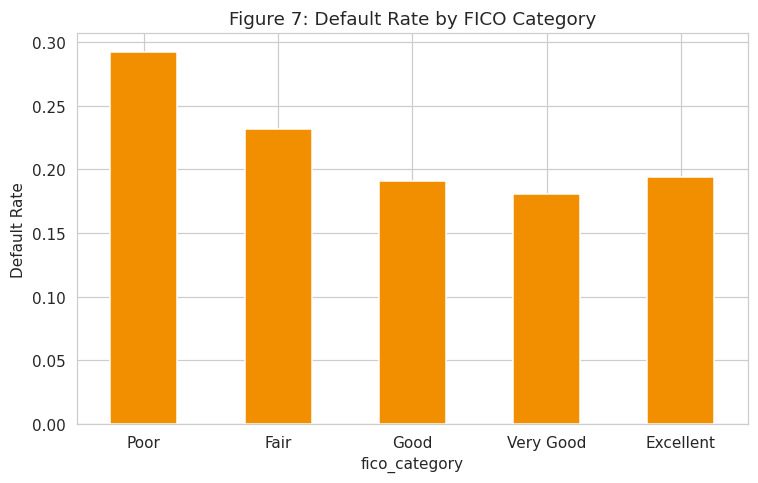

,loan_default
fico_category,
Poor,0.292285
Fair,0.231996
Good,0.190933
Very Good,0.180602
Excellent,0.193986


In [15]:
rate2 = df.groupby('fico_category')['loan_default'].mean().reindex(
    ['Poor','Fair','Good','Very Good','Excellent'])
fig, ax = plt.subplots(figsize=(7,4.5))
rate2.plot(kind='bar', ax=ax, color='#F18F01')
ax.set_ylabel('Default Rate')
ax.set_title('Figure 7: Default Rate by FICO Category')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
rate2


**Insight:** Default rate broadly decreases as FICO category improves from *Poor* to *Very Good*, validating the FICO categorisation as a sound risk signal, with a slight uptick at *Excellent* likely attributable to sample noise / small-sample effects in that band.

### 4.8 Multivariate Analysis — Interest Rate by Default Status

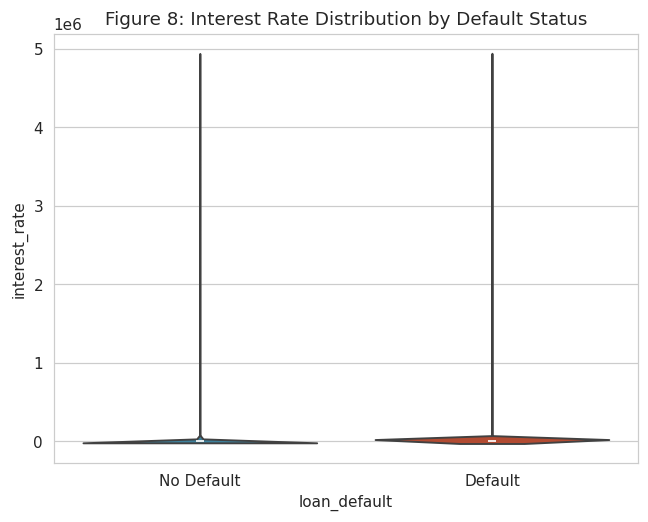

In [16]:
fig, ax = plt.subplots(figsize=(6,5))
sns.violinplot(x='loan_default', y='interest_rate', hue='loan_default', data=df,
               ax=ax, palette=['#2E86AB','#C73E1D'], legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels(['No Default','Default'])
ax.set_title('Figure 8: Interest Rate Distribution by Default Status')
plt.tight_layout()
plt.show()


**Insight:** Defaulted loans tend to carry higher interest rates on average, consistent with risk-based pricing already partially reflecting borrower risk at origination.

### 4.9 Temporal Trend — Loan Volume and Default Rate by Year

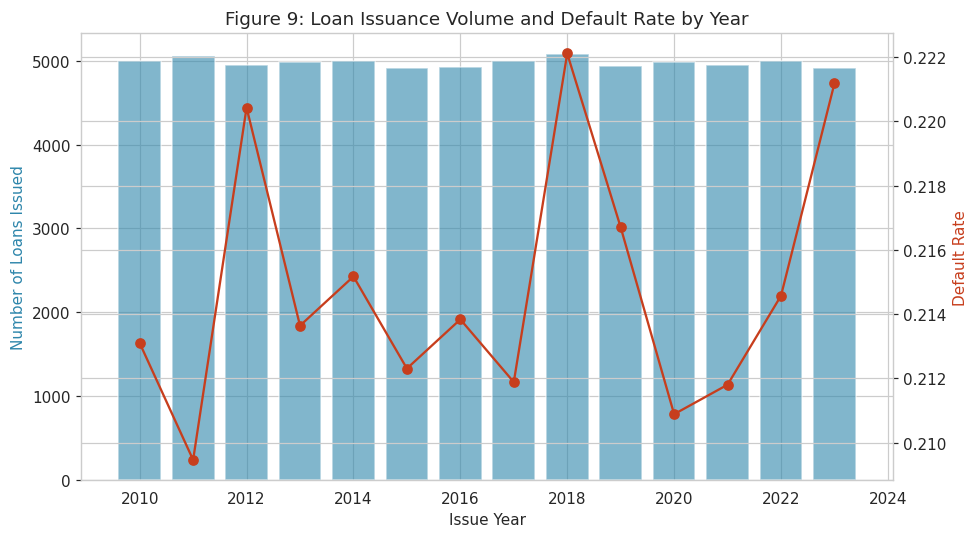

In [17]:
trend = df.groupby('issue_year').agg(volume=('loan_amount','count'), default_rate=('loan_default','mean'))
trend = trend[(trend.index >= 2010) & (trend.index <= 2024)]
fig, ax1 = plt.subplots(figsize=(9,5))
ax1.bar(trend.index, trend['volume'], color='#2E86AB', alpha=0.6, label='Loan Volume')
ax1.set_ylabel('Number of Loans Issued', color='#2E86AB')
ax2 = ax1.twinx()
ax2.plot(trend.index, trend['default_rate'], color='#C73E1D', marker='o', label='Default Rate')
ax2.set_ylabel('Default Rate', color='#C73E1D')
ax1.set_title('Figure 9: Loan Issuance Volume and Default Rate by Year')
ax1.set_xlabel('Issue Year')
plt.tight_layout()
plt.show()


**Insight:** Loan issuance volume and default rate both fluctuate year-on-year without a strong secular trend, suggesting default risk in this portfolio is driven more by borrower- and loan-level attributes than by macro/vintage effects alone.

### 4.10 Bivariate Analysis — Default by Home Ownership

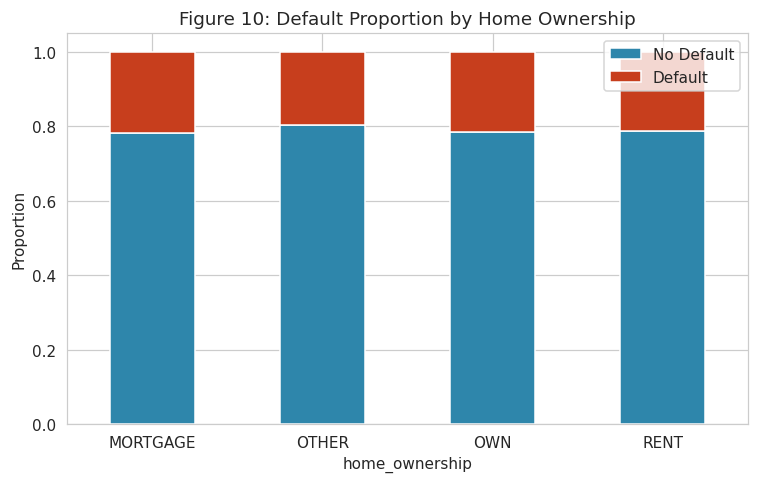

In [18]:
ct = pd.crosstab(df['home_ownership'], df['loan_default'], normalize='index')
fig, ax = plt.subplots(figsize=(7,4.5))
ct.plot(kind='bar', stacked=True, ax=ax, color=['#2E86AB','#C73E1D'])
ax.set_title('Figure 10: Default Proportion by Home Ownership')
ax.set_ylabel('Proportion')
ax.legend(['No Default','Default'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Insight:** Borrowers who rent show a marginally higher default proportion than those with a
mortgage or who own outright, consistent with home-owning borrowers typically having greater
financial stability/collateral.

### 4.11 Summary of EDA Insights
- Overall portfolio default rate: **21.5%** (moderate class imbalance).
- Strongest individual risk indicators: **`risk_score`**, **`credit_score`**, **`dti_ratio`**,
  **`inquiries_6m`**, **`delinq_2yrs`**.
- **Loan purpose** and **home ownership** are meaningful segment-level differentiators of default
  risk, useful for policy-level segmentation.
- **Region** does not show a strong standalone relationship with credit score or default in this
  portfolio.
- **Interest rate** already partially reflects borrower risk at origination, but leaves room for a
  model-based approach to further refine risk-based pricing.
- These findings motivate the choice of predictive models (Logistic Regression as an interpretable
  baseline; Tree-based and ensemble models such as Random Forest, Gradient Boosting/XGBoost to
  capture non-linear interactions) to be developed in the Final Report.


### 4.12 Categorical Analysis — Loan Purpose

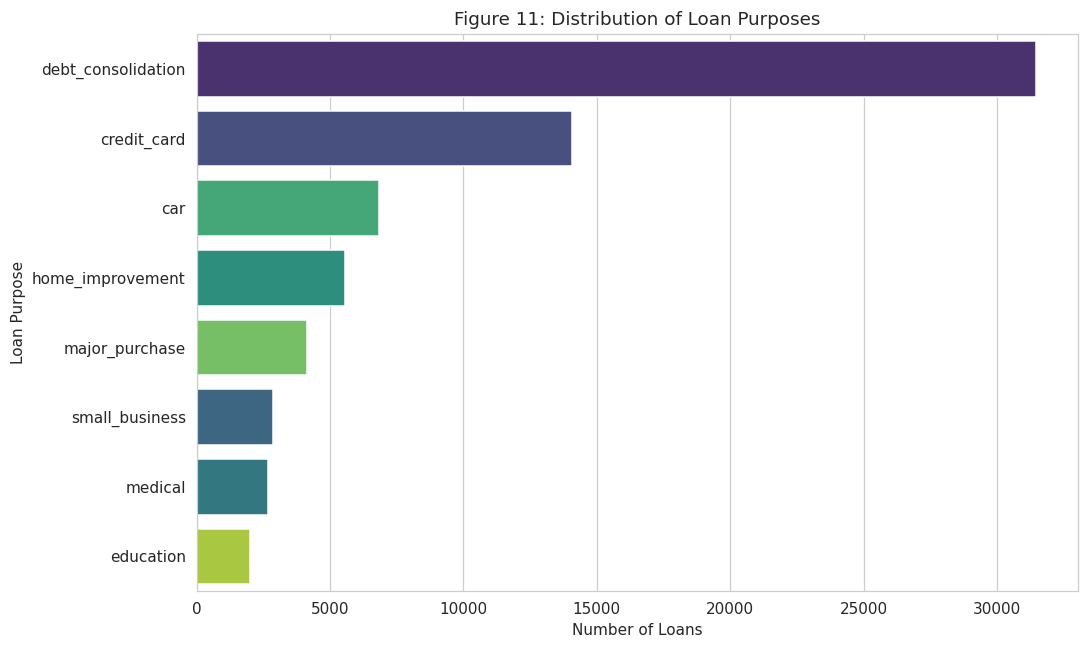

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(y='loan_purpose', data=df, order=df['loan_purpose'].value_counts().index, palette='viridis', hue='loan_purpose', legend=False)
ax.set_title('Figure 11: Distribution of Loan Purposes')
ax.set_xlabel('Number of Loans')
ax.set_ylabel('Loan Purpose')
plt.tight_layout()
plt.show()

**Insight:** A significant portion of loans are for `debt_consolidation` and `credit_card` purposes, indicating a large segment of borrowers using loans to manage existing debt. This suggests a potential risk factor, as borrowers might be taking on new debt to pay off old ones. `home_improvement` and `major_purchase` also represent substantial categories, reflecting common large-ticket spending reasons.

### 4.13 Categorical Analysis — Default Status Comparisons

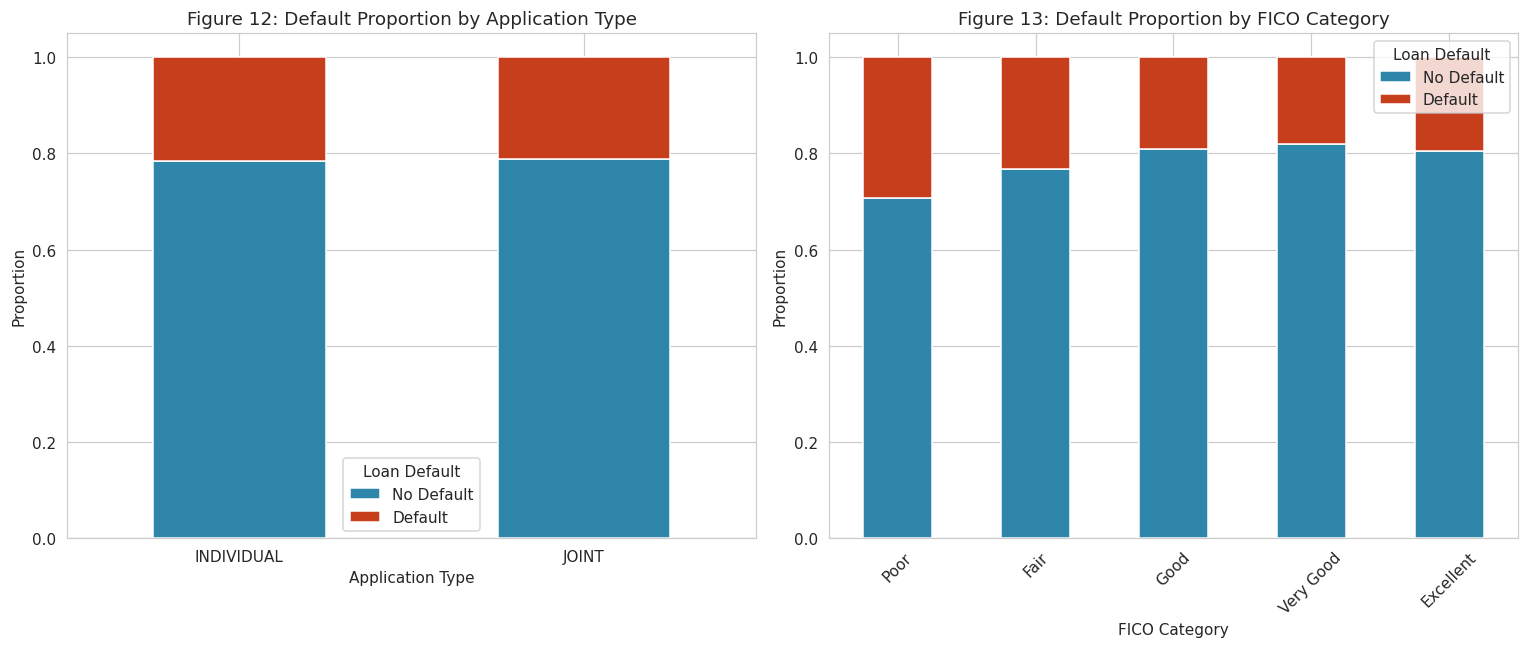

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Stacked bar plot for Application Type vs Default Status
ct_app_type = pd.crosstab(df['application_type'], df['loan_default'], normalize='index')
ct_app_type.plot(kind='bar', stacked=True, ax=axes[0], color=['#2E86AB', '#C73E1D'])
axes[0].set_title('Figure 12: Default Proportion by Application Type')
axes[0].set_ylabel('Proportion')
axes[0].set_xlabel('Application Type')
axes[0].legend(['No Default', 'Default'], title='Loan Default')
axes[0].tick_params(axis='x', rotation=0)

# Stacked bar plot for FICO Category vs Default Status
ct_fico = pd.crosstab(df['fico_category'], df['loan_default'], normalize='index').reindex(
    ['Poor', 'Fair', 'Good', 'Very Good', 'Excellent'])
ct_fico.plot(kind='bar', stacked=True, ax=axes[1], color=['#2E86AB', '#C73E1D'])
axes[1].set_title('Figure 13: Default Proportion by FICO Category')
axes[1].set_ylabel('Proportion')
axes[1].set_xlabel('FICO Category')
axes[1].legend(['No Default', 'Default'], title='Loan Default')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Insight:**
*   `INDIVIDUAL` applications have a slightly higher default proportion compared to `JOINT` applications, though the difference is minimal. This suggests that the type of application alone might not be a strong predictor.
*   The default rate clearly decreases as the FICO category improves, reinforcing the importance of credit score as a risk indicator. *Poor* FICO categories exhibit the highest default rates, while *Excellent* categories show the lowest. The slight increase in default for *Excellent* FICO seen previously might be noise, but it's important to keep in mind.

### 4.14 Categorical Analysis — Region Analysis

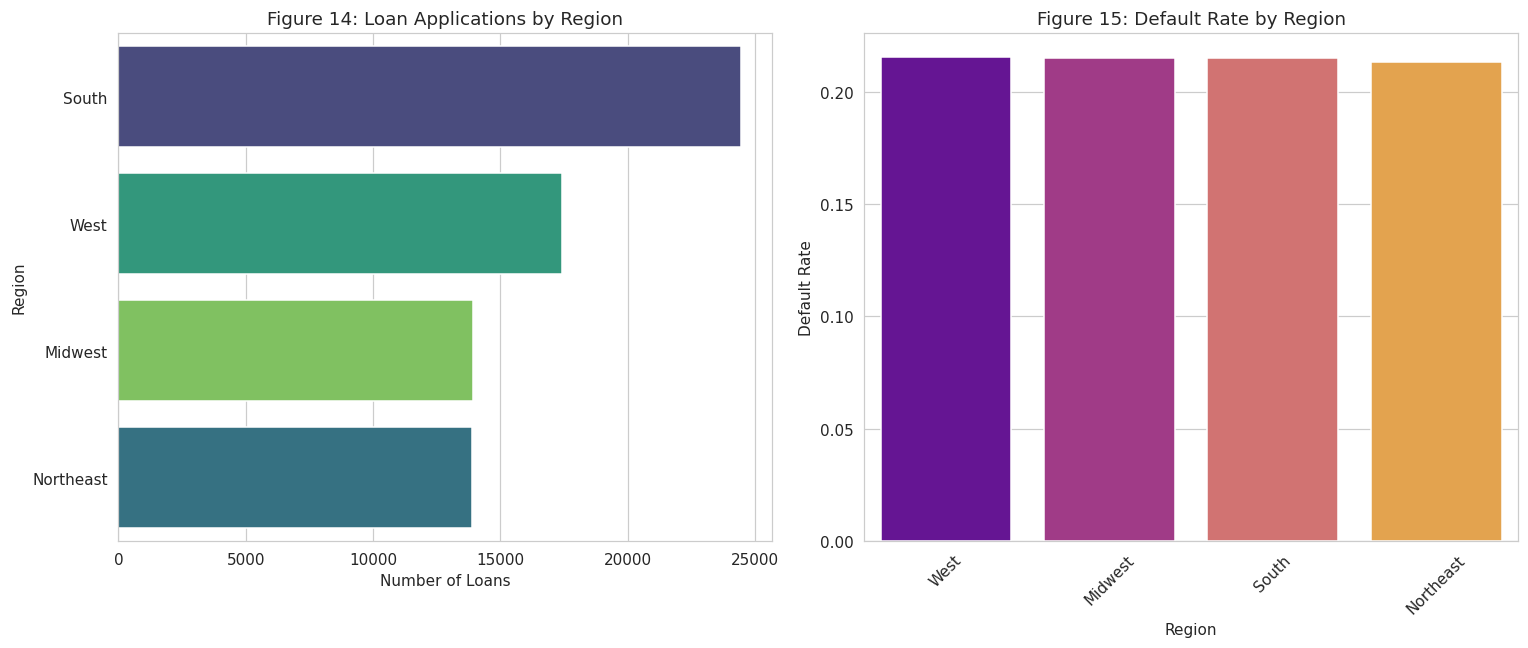

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Region-wise loan applications (counts)
sns.countplot(y='region', data=df, order=df['region'].value_counts().index, ax=axes[0], palette='viridis', hue='region', legend=False)
axes[0].set_title('Figure 14: Loan Applications by Region')
axes[0].set_xlabel('Number of Loans')
axes[0].set_ylabel('Region')

# Region-wise default rate
region_default_rate = df.groupby('region')['loan_default'].mean().sort_values(ascending=False)
sns.barplot(x=region_default_rate.index, y=region_default_rate.values, ax=axes[1], palette='plasma', hue=region_default_rate.index, legend=False)
axes[1].set_title('Figure 15: Default Rate by Region')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Default Rate')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Insight:**
*   The `South` region accounts for the highest number of loan applications, followed by `Northeast`. This indicates that these regions are key markets for FinWise Lending Co.
*   Despite having the highest volume, the `South` region does not necessarily have the highest default rate. The default rates are relatively similar across regions, with `Midwest` showing a slightly higher average default rate and `West` showing a slightly lower one. This confirms the earlier insight that region alone may not be a strong differentiator of creditworthiness, but it's important to monitor performance in high-volume regions.

In [22]:
df.head()

,borrower_id,age,employment_length,home_ownership,annual_income,dti_ratio,revolving_utilization,open_credit_lines,total_credit_lines,loan_amount,term,interest_rate,installment_amount,loan_purpose,application_type,credit_score,delinq_2yrs,inquiries_6m,fico_category,loan_status,loan_default,utilization_ratio,risk_score,region,issue_date,last_payment_date,income_to_loan_ratio,issue_year,credit_age_years
0,B100000,42.0,11.0,MORTGAGE,50240.95,6.01,47.59,4.0,7.0,21573.0,36.0,11.30,666.97,debt_consolidation,INDIVIDUAL,614.0,0.0,0.0,Fair,Fully Paid,0,0.4294,79.29,South,2012-09-20,2026-05-22,2.328881,2012,13.667351
1,B100001,36.0,5.0,RENT,22221.29,17.77,53.11,2.0,6.0,5474.0,60.0,15.15,105.06,credit_card,INDIVIDUAL,635.0,2.0,0.0,Fair,Charged Off,1,0.2463,54.04,Northeast,2012-04-25,2024-06-16,4.059425,2012,12.142368
2,B100002,44.0,5.0,MORTGAGE,42457.94,0.00,145.36,5.0,8.0,17501.0,60.0,10.61,322.63,small_business,INDIVIDUAL,669.0,0.0,0.0,Fair,Fully Paid,0,0.4122,84.24,West,2014-10-14,2016-07-15,2.426029,2014,1.752225
3,B100003,53.0,3.0,RENT,26979.11,23.68,123.11,3.0,5.0,6398.0,36.0,13.31,201.38,credit_card,INDIVIDUAL,666.0,1.0,0.0,Fair,Late,1,0.2371,65.43,Northeast,2023-08-06,2016-03-02,4.216804,2023,-7.427789
4,B100004,35.0,6.0,RENT,40646.44,21.33,14.47,6.0,8.0,11201.0,36.0,15.36,358.93,medical,INDIVIDUAL,617.0,0.0,0.0,Fair,Fully Paid,0,0.2756,73.46,Northeast,2014-04-17,2019-12-30,3.628822,2014,5.702943


In [23]:
df.shape

(69654, 29)

In [24]:
print(pd.crosstab(df['loan_status'], df['loan_default']))

loan_default      0     1
loan_status              
Charged Off       0  8948
Fully Paid    54693    26
Late              0  5987


In [25]:
import pandas as pd
import numpy as np
import re
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (ExtraTreesClassifier, BaggingClassifier, RandomForestClassifier,
                               AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

# 4. Train/Test Split & Preprocessing Pipeline (Chapter V)
borrower_id (identifier), loan_status (target leakage), and the two raw date columns (superseded by issue_year / credit_age_years) are excluded from the feature set. An 80/20 stratified split preserves the 21.5% default rate in both partitions.

In [26]:
drop_cols = ['borrower_id', 'loan_status', 'issue_date', 'last_payment_date']
target = 'loan_default'

y = df[target]
X = df.drop(columns=drop_cols + [target])

num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()
print("Numeric features:", num_features)
print("Categorical features:", cat_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train default rate:", y_train.mean().round(4), " Test default rate:", y_test.mean().round(4))

Numeric features: ['age', 'employment_length', 'annual_income', 'dti_ratio', 'revolving_utilization', 'open_credit_lines', 'total_credit_lines', 'loan_amount', 'term', 'interest_rate', 'installment_amount', 'credit_score', 'delinq_2yrs', 'inquiries_6m', 'utilization_ratio', 'risk_score', 'income_to_loan_ratio', 'issue_year', 'credit_age_years']
Categorical features: ['home_ownership', 'loan_purpose', 'application_type', 'fico_category', 'region']
Train shape: (55723, 24)  Test shape: (13931, 24)
Train default rate: 0.2148  Test default rate: 0.2148


# One-Hot Encoding
goal is simply to identify object/category columns and One-Hot Encode them

In [39]:
X_train

,age,employment_length,annual_income,dti_ratio,revolving_utilization,open_credit_lines,total_credit_lines,loan_amount,term,interest_rate,installment_amount,credit_score,delinq_2yrs,inquiries_6m,utilization_ratio,...,loan_purpose_home_improvement,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_small_business,application_type_INDIVIDUAL,application_type_JOINT,fico_category_Excellent,fico_category_Fair,fico_category_Good,fico_category_Poor,fico_category_Very Good,region_Midwest,region_Northeast,region_South,region_West
0,26.000000,24.000000,49887.080000,14.330000,46.380000,5.000000,9.000000,11067.000000,36.000000,11.350000,342.310000,628.000000,0.000000,1.000000,0.221800,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
1,44.000000,3.000000,8000.000000,29.070000,43.380000,7.000000,9.000000,1719.000000,36.000000,15.220000,55.020000,681.000000,0.000000,1.000000,0.214800,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,1.000000,0.0,0.0,0.000000,0.000000,0.000000,1.000000
2,47.000000,4.000000,16358.790000,8.120000,64.480000,2.000000,5.000000,5717.000000,36.000000,13.520000,180.280000,699.000000,1.000000,0.000000,0.349500,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,1.000000,0.0,0.0,1.000000,0.000000,0.000000,0.000000
3,48.000000,12.000000,69591.370000,14.270000,64.370000,5.000000,8.000000,17113.000000,60.000000,15.230000,328.660000,625.000000,0.000000,1.000000,0.245900,...,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
4,38.000000,10.000000,10695.660000,20.340000,99.490000,6.000000,7.000000,2983.000000,36.000000,8.600000,89.990000,620.000000,1.000000,1.000000,0.278900,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87503,41.126747,18.123459,28093.715301,2.461652,69.302362,6.125103,6.375308,9503.118527,39.002466,14.206321,286.398847,614.622226,0.125103,2.624692,0.338249,...,0.874897,0.0,0.0,0.0,1.0,0.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
87504,42.655622,2.302432,43310.377413,16.301178,74.728744,4.739514,7.520973,21374.061355,60.000000,13.744018,405.174607,645.200915,0.520973,0.739514,0.493467,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.739514,0.260486,0.0,0.0,0.260486,0.000000,0.000000,0.739514
87505,38.838742,3.806291,9567.007821,14.339994,28.501427,3.000000,0.322516,6335.514232,36.000000,12.133520,197.341503,635.770850,0.000000,1.322516,0.618228,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.838742,0.161258,0.0,0.0,0.000000,0.838742,0.161258,0.000000
87506,38.047651,11.253687,48308.801100,13.098207,26.802492,3.682550,7.047651,19618.348990,43.618788,14.640905,543.308224,670.571818,0.317450,2.365101,0.406108,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.317450,0.682550,0.0,0.0,0.000000,0.000000,0.317450,0.682550


In [28]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import numpy as np

# Identify categorical columns
cat_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical columns:")
print(cat_features)


# One-Hot Encoding
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit on training data and transform
X_train_cat = encoder.fit_transform(X_train[cat_features])

# Transform test data using the same encoder
X_test_cat = encoder.transform(X_test[cat_features])


# Get encoded column names
encoded_columns = encoder.get_feature_names_out(cat_features)


# Convert encoded data to DataFrames
X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoded_columns,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=encoded_columns,
    index=X_test.index
)


# Remove original categorical columns
X_train_num = X_train.drop(columns=cat_features)
X_test_num = X_test.drop(columns=cat_features)


# Combine numerical + encoded categorical columns
X_train = pd.concat(
    [X_train_num, X_train_cat],
    axis=1
)

X_test = pd.concat(
    [X_test_num, X_test_cat],
    axis=1
)


print("Encoded X_train shape:", X_train.shape)
print("Encoded X_test shape:", X_test.shape)

Categorical columns:
['home_ownership', 'loan_purpose', 'application_type', 'fico_category', 'region']
Encoded X_train shape: (55723, 42)
Encoded X_test shape: (13931, 42)


# SMOTE for class imbalance
Check class distribution BEFORE SMOTE & Apply SMOTE ONLY to training data

In [29]:
from imblearn.over_sampling import SMOTE
# =========================================================
# 1. Check class distribution BEFORE SMOTE
# =========================================================

print("\nClass distribution BEFORE SMOTE:")
print(y_train.value_counts())

print("\nClass proportions BEFORE SMOTE:")
print(y_train.value_counts(normalize=True))


# =========================================================
# 2. Apply SMOTE ONLY to training data
# =========================================================

smote = SMOTE(
    random_state=42
)

X_train, y_train = smote.fit_resample(
    X_train,
    y_train
)


# =========================================================
# 3. Check class distribution AFTER SMOTE
# =========================================================

print("\nClass distribution AFTER SMOTE:")
print(y_train.value_counts())

print("\nClass proportions AFTER SMOTE:")
print(y_train.value_counts(normalize=True))


# =========================================================
# 4. Final shapes
# =========================================================

print("\nFinal training shape after SMOTE:")
print(X_train.shape)

print("\nTest shape:")
print(X_test.shape)


Class distribution BEFORE SMOTE:
loan_default
0    43754
1    11969
Name: count, dtype: int64

Class proportions BEFORE SMOTE:
loan_default
0    0.785205
1    0.214795
Name: proportion, dtype: float64

Class distribution AFTER SMOTE:
loan_default
0    43754
1    43754
Name: count, dtype: int64

Class proportions AFTER SMOTE:
loan_default
0    0.5
1    0.5
Name: proportion, dtype: float64

Final training shape after SMOTE:
(87508, 42)

Test shape:
(13931, 42)


# Imports & Calculate class imbalance


In [30]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 1.0


# Defining the models
we are not putting the parameters we want to optimize directly into the models. The parameters will be supplied through param_grids.

In [35]:
# @title
models = {

    'Logistic Regression': LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    'Naive Bayes': GaussianNB(),

    'KNN': KNeighborsClassifier(
        n_jobs=-1
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    )

#    'Random Forest': RandomForestClassifier(
#        random_state=42,
#        n_jobs=-1
#    ),

#    'Gradient Boosting': GradientBoostingClassifier(
#        random_state=42
#    ),

#    'XGBoost': XGBClassifier(
#        eval_metric='logloss',
#        random_state=42,
#        n_jobs=-1
#    )
}

# Define the GridSearchCV parameter grids


In [36]:
param_grids = {

    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['liblinear', 'lbfgs'],
        'class_weight': ['balanced', None]
    },

    'Naive Bayes': {
        'var_smoothing': np.logspace(-12, -6, 7)
    },

    'KNN': {
        'n_neighbors': [5, 10, 15, 20, 25, 30, 35, 40],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    },

    'Decision Tree': {
        'max_depth': [3, 5, 7, 9, 12, 15, None],
        'min_samples_split': [2, 5, 10, 20],
        'min_samples_leaf': [1, 2, 5, 10],
        'criterion': ['gini', 'entropy'],
        'class_weight': ['balanced', None]
    }

#    'Random Forest': {
#        'n_estimators': [100, 200, 300, 500],
#        'max_depth': [None, 8, 12, 16, 20],
#        'min_samples_split': [2, 5, 10],
#        'min_samples_leaf': [1, 2, 5],
#        'max_features': ['sqrt', 'log2'],
#        'class_weight': ['balanced', 'balanced_subsample', None]
#    },
#
#    'Gradient Boosting': {
#        'n_estimators': [50, 100, 150, 200],
#        'learning_rate': [0.01, 0.05, 0.1, 0.2],
#        'max_depth': [2, 3, 4, 5],
#        'subsample': [0.7, 0.8, 0.9, 1.0],
#        'min_samples_split': [2, 5, 10]
#    },
#
#    'XGBoost': {
#        'n_estimators': [100, 200, 300, 500],
#        'max_depth': [3, 4, 5, 6, 8],
#        'learning_rate': [0.01, 0.05, 0.1, 0.2],
#        'subsample': [0.7, 0.8, 0.9, 1.0],
#        'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
#        'min_child_weight': [1, 3, 5],
#        'gamma': [0, 0.1, 0.3],
#        'scale_pos_weight': [scale_pos_weight]
#    }
}

# Set up Stratified K-Fold
StratifiedKFold recommended because it maintains the proportion of Default/non-default observations in each fold.

In [37]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Run GridSearchCV for every model
Recall is used as the optimization metric.

In [ ]:
best_models = {}
grid_results = []

for name in models:

    print("\n" + "=" * 70)
    print(f"Running GridSearchCV for: {name}")
    print("=" * 70)

    grid = GridSearchCV(
        estimator=models[name],
        param_grid=param_grids[name],
        scoring='recall',       # Optimize for Recall
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    grid.fit(X_train, y_train)

    # Store best model
    best_models[name] = grid.best_estimator_

    # Store results
    grid_results.append({
        'Model': name,
        'Best CV Recall': grid.best_score_,
        'Best Parameters': grid.best_params_
    })

    print(f"\nBest Recall Score: {grid.best_score_:.4f}")
    print("Best Parameters:")
    print(grid.best_params_)


Running GridSearchCV for: Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Recall Score: 0.5637
Best Parameters:
{'C': 100, 'class_weight': None, 'solver': 'lbfgs'}

Running GridSearchCV for: Naive Bayes
Fitting 5 folds for each of 7 candidates, totalling 35 fits

Best Recall Score: 0.9813
Best Parameters:
{'var_smoothing': np.float64(1e-08)}

Running GridSearchCV for: KNN
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Best Recall Score: 0.9153
Best Parameters:
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}

Running GridSearchCV for: Decision Tree
Fitting 5 folds for each of 448 candidates, totalling 2240 fits

Best Recall Score: 0.7862
Best Parameters:
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Running GridSearchCV for: Random Forest
Fitting 5 folds for each of 1080 candidates, totalling 5400 fits


In [33]:
models = {

    'Random Forest': RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )

#    'XGBoost': XGBClassifier(
#        eval_metric='logloss',
#        random_state=42,
#        n_jobs=-1
#    )
}

param_grid_1 = {

    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [8, 15, None],
        'min_samples_split': [5, 10],
        'min_samples_leaf': [2, 5],
        'max_features': ['sqrt'],
        'class_weight': ['balanced']
    },

    'Gradient Boosting': {
        'n_estimators': [100, 200],
        'learning_rate': [0.05, 0.1],
        'max_depth': [2, 3],
        'subsample': [0.8, 1.0],
        'min_samples_split': [5, 10]
    }

#    'XGBoost': {
#        'n_estimators': [100, 200],
#        'max_depth': [3, 5],
#        'learning_rate': [0.05, 0.1],
#        'subsample': [0.8, 1.0],
#        'colsample_bytree': [0.8, 1.0],
#        'min_child_weight': [1, 3],
#        'gamma': [0],
#        'scale_pos_weight': [scale_pos_weight]
#    }
}

In [34]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [35]:
best_models = {}
grid_results = []

for name in models:

    print("\n" + "=" * 70)
    print(f"Running GridSearchCV for: {name}")
    print("=" * 70)

    grid = GridSearchCV(
        estimator=models[name],
        param_grid=param_grid_1[name],
        scoring='recall',       # Optimize for Recall
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    grid.fit(X_train, y_train)

    # Store best model
    best_models[name] = grid.best_estimator_

    # Store results
    grid_results.append({
        'Model': name,
        'Best CV Recall': grid.best_score_,
        'Best Parameters': grid.best_params_
    })

    print(f"\nBest Recall Score: {grid.best_score_:.4f}")
    print("Best Parameters:")
    print(grid.best_params_)


Running GridSearchCV for: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Recall Score: 0.7261
Best Parameters:
{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}

Running GridSearchCV for: Gradient Boosting
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Best Recall Score: 0.7251
Best Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 10, 'n_estimators': 200, 'subsample': 0.8}

Running GridSearchCV for: XGBoost
Fitting 5 folds for each of 64 candidates, totalling 320 fits


KeyboardInterrupt: 

In [31]:
models = {

    'XGBoost': XGBClassifier(
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

param_grid_2 = {

    'XGBoost': {
        'n_estimators': [100, 200],
        'max_depth': [3, 5],
        'learning_rate': [0.05, 0.1],
        'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0],
        'min_child_weight': [1, 3],
        'gamma': [0],
        'scale_pos_weight': [scale_pos_weight]
    }
}

In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
best_models = {}
grid_results = []

for name in models:

    print("\n" + "=" * 70)
    print(f"Running GridSearchCV for: {name}")
    print("=" * 70)

    grid = GridSearchCV(
        estimator=models[name],
        param_grid=param_grid_2[name],
        scoring='recall',       # Optimize for Recall
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    grid.fit(X_train, y_train)

    # Store best model
    best_models[name] = grid.best_estimator_

    # Store results
    grid_results.append({
        'Model': name,
        'Best CV Recall': grid.best_score_,
        'Best Parameters': grid.best_params_
    })

    print(f"\nBest Recall Score: {grid.best_score_:.4f}")
    print("Best Parameters:")
    print(grid.best_params_)


Running GridSearchCV for: XGBoost
Fitting 5 folds for each of 64 candidates, totalling 320 fits

Best Recall Score: 0.7266
Best Parameters:
{'colsample_bytree': 1.0, 'gamma': 0, 'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 3, 'n_estimators': 200, 'scale_pos_weight': np.float64(1.0), 'subsample': 0.8}


# Optimized Model Comparison

In [34]:
import pandas as pd

# ============================================================
# GridSearchCV optimized model results
# ============================================================

results = [
    {
        'Model': 'Logistic Regression',
        'Best Recall': 0.5637,
        'Best Parameters': {
            'C': 100,
            'class_weight': None,
            'solver': 'lbfgs'
        }
    },

    {
        'Model': 'Naive Bayes',
        'Best Recall': 0.9813,
        'Best Parameters': {
            'var_smoothing': 1e-08
        }
    },

    {
        'Model': 'KNN',
        'Best Recall': 0.9153,
        'Best Parameters': {
            'metric': 'manhattan',
            'n_neighbors': 5,
            'weights': 'distance'
        }
    },

    {
        'Model': 'Decision Tree',
        'Best Recall': 0.7862,
        'Best Parameters': {
            'class_weight': 'balanced',
            'criterion': 'gini',
            'max_depth': None,
            'min_samples_leaf': 1,
            'min_samples_split': 2
        }
    },

    {
        'Model': 'Random Forest',
        'Best Recall': 0.7261,
        'Best Parameters': {
            'class_weight': 'balanced',
            'max_depth': None,
            'max_features': 'sqrt',
            'min_samples_leaf': 2,
            'min_samples_split': 5,
            'n_estimators': 100
        }
    },

    {
        'Model': 'Gradient Boosting',
        'Best Recall': 0.7251,
        'Best Parameters': {
            'learning_rate': 0.1,
            'max_depth': 3,
            'min_samples_split': 10,
            'n_estimators': 200,
            'subsample': 0.8
        }
    },

    {
        'Model': 'XGBoost',
        'Best Recall': 0.7266,
        'Best Parameters': {
            'colsample_bytree': 1.0,
            'gamma': 0,
            'learning_rate': 0.1,
            'max_depth': 5,
            'min_child_weight': 3,
            'n_estimators': 200,
            'scale_pos_weight': 1.0,
            'subsample': 0.8
        }
    }
]


# ============================================================
# Create DataFrame
# ============================================================

comparison_df = pd.DataFrame(results)


# ============================================================
# Sort by Recall
# ============================================================

comparison_df = comparison_df.sort_values(
    by='Best Recall',
    ascending=False
).reset_index(drop=True)


# ============================================================
# Add Rank
# ============================================================

comparison_df.insert(
    0,
    'Rank',
    range(1, len(comparison_df) + 1)
)


# ============================================================
# Format Recall
# ============================================================

comparison_df['Best Recall'] = comparison_df['Best Recall'].map(
    lambda x: f"{x:.4f}"
)


# ============================================================
# Display
# ============================================================

display(comparison_df)

,Rank,Model,Best Recall,Best Parameters
0,1,Naive Bayes,0.9813,{'var_smoothing': 1e-08}
1,2,KNN,0.9153,"{'metric': 'manhattan', 'n_neighbors': 5, 'wei..."
2,3,Decision Tree,0.7862,"{'class_weight': 'balanced', 'criterion': 'gin..."
3,4,XGBoost,0.7266,"{'colsample_bytree': 1.0, 'gamma': 0, 'learnin..."
4,5,Random Forest,0.7261,"{'class_weight': 'balanced', 'max_depth': None..."
5,6,Gradient Boosting,0.7251,"{'learning_rate': 0.1, 'max_depth': 3, 'min_sa..."
6,7,Logistic Regression,0.5637,"{'C': 100, 'class_weight': None, 'solver': 'lb..."


In [40]:
X_train

,age,employment_length,annual_income,dti_ratio,revolving_utilization,open_credit_lines,total_credit_lines,loan_amount,term,interest_rate,installment_amount,credit_score,delinq_2yrs,inquiries_6m,utilization_ratio,...,loan_purpose_home_improvement,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_small_business,application_type_INDIVIDUAL,application_type_JOINT,fico_category_Excellent,fico_category_Fair,fico_category_Good,fico_category_Poor,fico_category_Very Good,region_Midwest,region_Northeast,region_South,region_West
0,26.000000,24.000000,49887.080000,14.330000,46.380000,5.000000,9.000000,11067.000000,36.000000,11.350000,342.310000,628.000000,0.000000,1.000000,0.221800,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
1,44.000000,3.000000,8000.000000,29.070000,43.380000,7.000000,9.000000,1719.000000,36.000000,15.220000,55.020000,681.000000,0.000000,1.000000,0.214800,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,1.000000,0.0,0.0,0.000000,0.000000,0.000000,1.000000
2,47.000000,4.000000,16358.790000,8.120000,64.480000,2.000000,5.000000,5717.000000,36.000000,13.520000,180.280000,699.000000,1.000000,0.000000,0.349500,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,1.000000,0.0,0.0,1.000000,0.000000,0.000000,0.000000
3,48.000000,12.000000,69591.370000,14.270000,64.370000,5.000000,8.000000,17113.000000,60.000000,15.230000,328.660000,625.000000,0.000000,1.000000,0.245900,...,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
4,38.000000,10.000000,10695.660000,20.340000,99.490000,6.000000,7.000000,2983.000000,36.000000,8.600000,89.990000,620.000000,1.000000,1.000000,0.278900,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87503,41.126747,18.123459,28093.715301,2.461652,69.302362,6.125103,6.375308,9503.118527,39.002466,14.206321,286.398847,614.622226,0.125103,2.624692,0.338249,...,0.874897,0.0,0.0,0.0,1.0,0.0,0.0,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000
87504,42.655622,2.302432,43310.377413,16.301178,74.728744,4.739514,7.520973,21374.061355,60.000000,13.744018,405.174607,645.200915,0.520973,0.739514,0.493467,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.739514,0.260486,0.0,0.0,0.260486,0.000000,0.000000,0.739514
87505,38.838742,3.806291,9567.007821,14.339994,28.501427,3.000000,0.322516,6335.514232,36.000000,12.133520,197.341503,635.770850,0.000000,1.322516,0.618228,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.838742,0.161258,0.0,0.0,0.000000,0.838742,0.161258,0.000000
87506,38.047651,11.253687,48308.801100,13.098207,26.802492,3.682550,7.047651,19618.348990,43.618788,14.640905,543.308224,670.571818,0.317450,2.365101,0.406108,...,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,0.317450,0.682550,0.0,0.0,0.000000,0.000000,0.317450,0.682550


In [42]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# Model classes
# ============================================================

model_classes = {
    'Logistic Regression': LogisticRegression,
    'Naive Bayes': GaussianNB,
    'KNN': KNeighborsClassifier,
    'Decision Tree': DecisionTreeClassifier,
    'Random Forest': RandomForestClassifier,
    'Gradient Boosting': GradientBoostingClassifier,
    'XGBoost': XGBClassifier
}


# ============================================================
# Train optimized models and evaluate on test data
# ============================================================

comparison = []

for result in results:

    model_name = result['Model']
    params = result['Best Parameters'].copy()

    # --------------------------------------------------------
    # Create model using optimized parameters
    # --------------------------------------------------------

    if model_name == 'Naive Bayes':

        # GaussianNB does not support random_state
        model = GaussianNB(**params)

    elif model_name == 'XGBoost':

        model = XGBClassifier(
            **params,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        )

    elif model_name == 'KNN':

        # KNN does not support random_state
        model = KNeighborsClassifier(**params, n_jobs=-1)

    else:

        model = model_classes[model_name](
            **params,
            random_state=42
        )

    # --------------------------------------------------------
    # Train optimized model
    # --------------------------------------------------------

    model.fit(X_train, y_train)

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    y_pred = model.predict(X_test)

    # --------------------------------------------------------
    # ROC-AUC score
    # --------------------------------------------------------

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # --------------------------------------------------------
    # Calculate metrics
    # --------------------------------------------------------

    comparison.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score)
    })


# ============================================================
# Create comparison table
# ============================================================

comparison_df = pd.DataFrame(comparison)

# Sort by Recall - highest first
comparison_df = comparison_df.sort_values(
    by='Recall',
    ascending=False
).reset_index(drop=True)

# Add rank
comparison_df.insert(
    0,
    'Rank',
    range(1, len(comparison_df) + 1)
)

# Round metrics
metric_columns = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC'
]

comparison_df[metric_columns] = comparison_df[metric_columns].round(4)

# Display
display(comparison_df)

,Rank,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1,Naive Bayes,0.2286,0.2152,0.9793,0.3529,0.5632
1,2,Logistic Regression,0.5649,0.2547,0.5328,0.3446,0.5740
2,3,KNN,0.5543,0.2179,0.4151,0.2857,0.5042
3,4,Decision Tree,0.6511,0.2233,0.2520,0.2368,0.5062
4,5,Random Forest,0.7851,0.4444,0.0027,0.0053,0.5713
5,6,XGBoost,0.7848,0.3125,0.0017,0.0033,0.5821
6,7,Gradient Boosting,0.7848,0.2500,0.0010,0.0020,0.5907


# Comparison of Recall and ROC-AUC for models

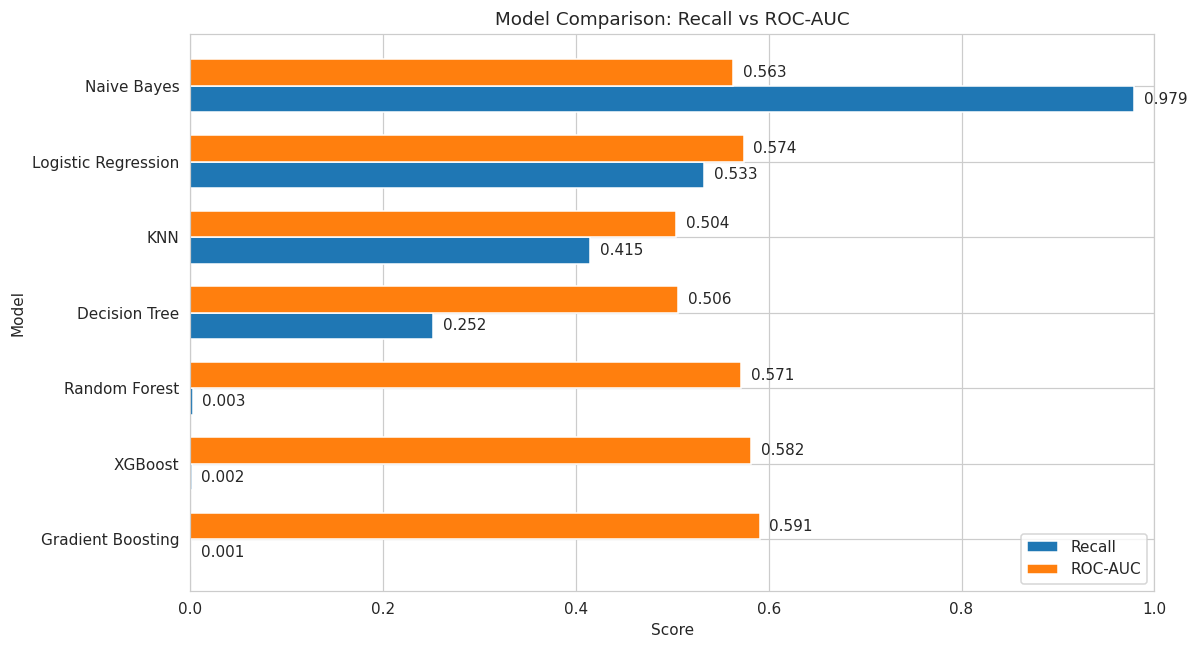

In [43]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = comparison_df.sort_values(
    by='Recall',
    ascending=True
)

y = np.arange(len(plot_df))
height = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.barh(
    y - height/2,
    plot_df['Recall'],
    height,
    label='Recall'
)

bars2 = plt.barh(
    y + height/2,
    plot_df['ROC-AUC'],
    height,
    label='ROC-AUC'
)

plt.yticks(y, plot_df['Model'])

plt.xlabel('Score')
plt.ylabel('Model')
plt.title('Model Comparison: Recall vs ROC-AUC')

plt.xlim(0, 1)
plt.legend()

# Add values to bars
for bar in bars1:
    plt.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height()/2,
        f'{bar.get_width():.3f}',
        va='center'
    )

for bar in bars2:
    plt.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height()/2,
        f'{bar.get_width():.3f}',
        va='center'
    )

plt.tight_layout()
plt.show()

# ROC Curve for best model

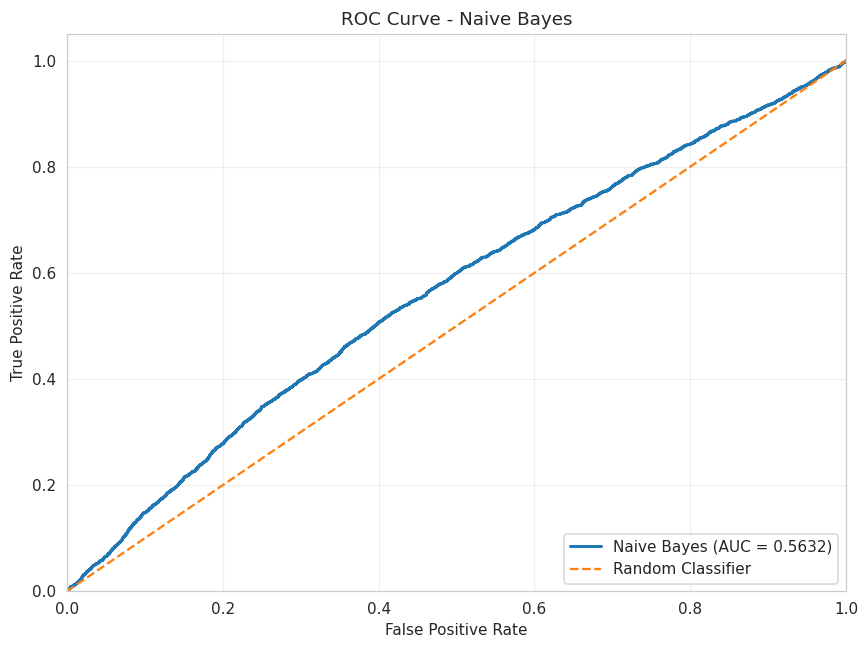

In [44]:
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve, roc_auc_score

# ============================================================
# Train optimized Naive Bayes model
# ============================================================

nb_model = GaussianNB(
    var_smoothing=1e-08
)

nb_model.fit(X_train, y_train)

# ============================================================
# Get predicted probabilities
# ============================================================

y_prob = nb_model.predict_proba(X_test)[:, 1]

# ============================================================
# Calculate ROC Curve
# ============================================================

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

# ============================================================
# Plot ROC Curve
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'Naive Bayes (AUC = {roc_auc:.4f})'
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Feature Importance with Best Model - Naive Bayes

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB

# --------------------------------------------------
# 1. Train optimized Naive Bayes model
# --------------------------------------------------

nb_model = GaussianNB(
    var_smoothing=1e-08
)

nb_model.fit(X_train, y_train)


# --------------------------------------------------
# 2. Calculate feature importance
# --------------------------------------------------

# Difference between class means
mean_difference = np.abs(
    nb_model.theta_[1] - nb_model.theta_[0]
)

# Average standard deviation across the two classes
average_std = (
    nb_model.var_[1] + nb_model.var_[0]
) / 2

# Standardized mean difference
feature_importance = mean_difference / np.sqrt(average_std)


# --------------------------------------------------
# 3. Create feature importance DataFrame
# --------------------------------------------------

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)


# Display feature importance
display(importance_df)

,Feature,Importance
0,risk_score,0.285373
1,credit_score,0.183646
2,dti_ratio,0.116056
3,revolving_utilization,0.061023
4,income_to_loan_ratio,0.036949
5,issue_year,0.035830
6,annual_income,0.029521
7,inquiries_6m,0.016919
8,employment_length,0.011633
9,installment_amount,0.011119


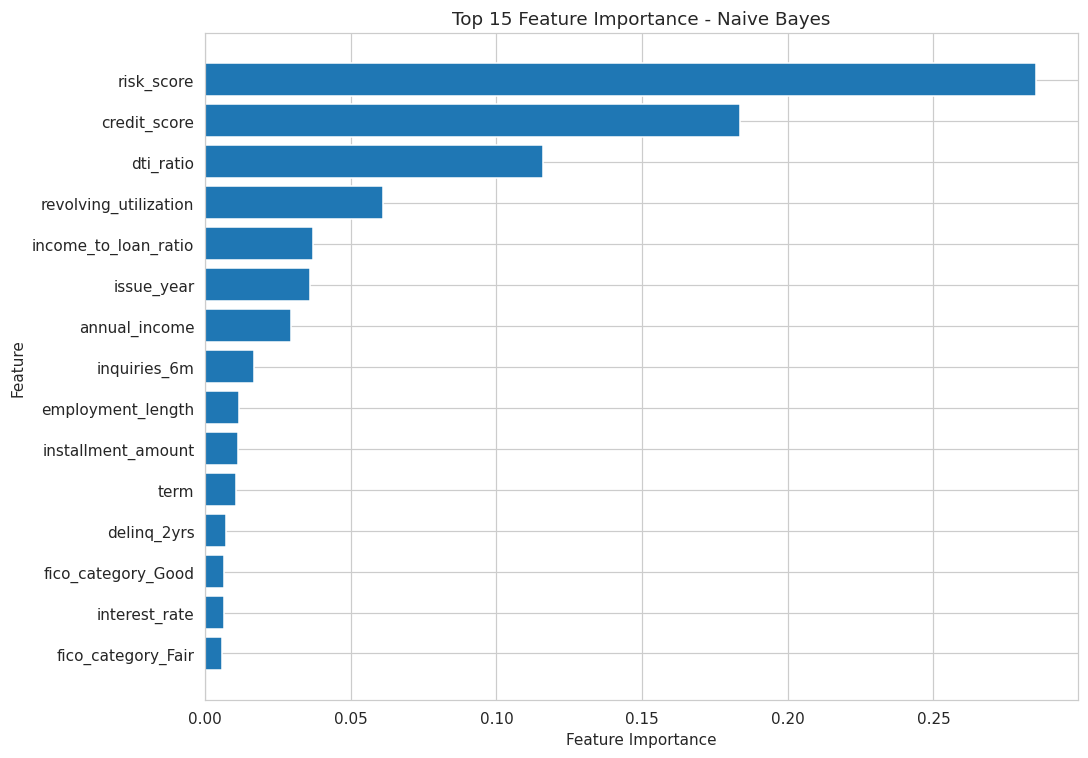

In [46]:
top_n = 15

top_features = importance_df.head(top_n).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importance - Naive Bayes')

plt.tight_layout()
plt.show()